In [3]:
pip install qiskit

Note: you may need to restart the kernel to use updated packages.


In [5]:
!pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [7]:
from qiskit import __version__

print(__version__)

2.5.2


In [9]:
import numpy as np
M1 = np.array([[1,1],[0,0]])
M2 = np.array([[1,0],[0,1]])
M = M1/2 + M2/2
print(M)

[[1.  0.5]
 [0.  0.5]]


## Operations

In [11]:
import numpy as np

ket0 = np.array([[1],[0]])
ket1 = np.array([[0],[1]])
print(ket0/2 + ket1/2)


[[0.5]
 [0.5]]


## Matrix Multiplication


In [13]:
print(M1 @ ket1, end='\n\n')
print(M1 @ M2, end='\n\n')
print(M @ M)


[[1]
 [0]]

[[1 1]
 [0 0]]

[[1.   0.75]
 [0.   0.25]]


## Better Visualization


In [15]:
from qiskit.visualization import array_to_latex

display(array_to_latex(M1 @ ket1))
display(array_to_latex(M1 @ M2))
display(array_to_latex(M @ M))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## Define and Display State Vectors

In [23]:
from qiskit.quantum_info import Statevector
from numpy import sqrt

u = Statevector([1 / sqrt(2), 1/sqrt(2)])
v = Statevector([(1+2j)/3, -2/3])
w = Statevector([1/3, 2/3])

## The Statevector class includes a 'draw' method for displaying state vectors in a variety of ways


In [25]:
display(u.draw("text"))
display(u.draw("latex"))
print(u.draw("latex_source"))
display(v.draw("latex"))

[0.70710678+0.j,0.70710678+0.j]

<IPython.core.display.Latex object>

\frac{\sqrt{2}}{2} |0\rangle+\frac{\sqrt{2}}{2} |1\rangle


<IPython.core.display.Latex object>

### The Statevector class also includes the 'is_valid' method, which checks to see if a given vector is valid quantum state vector (in other words, that it has Euclidean norm equal to 1)

In [23]:
display(u.is_valid())
display(w.is_valid())

True

False

## Simulating measurements using Statevector

In [25]:
display(v.draw("latex"))

<IPython.core.display.Latex object>

### 'measure' method simulates a standard basis measurement --> Quantum Circuits lesson will make it clearer

In [28]:
outcome, state = v.measure()
print(f"Measured: {outcome}\nPost-measurement state:")
display(state.draw("latex"))

Measured: 0
Post-measurement state:


<IPython.core.display.Latex object>

### 'sample_counts' method allows for the simulation of any number of measurements on the system, each time starting with a fresh copy of the state  --> leads us to understant the probability of states

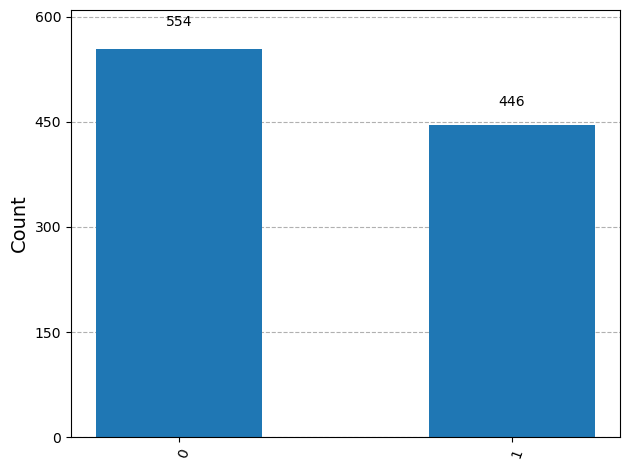

In [31]:
from qiskit.visualization import plot_histogram


statistics = v.sample_counts(1000)
plot_histogram(statistics)

## Perform operations with 'Operator' and 'Statevector' 

#### Unitary operations can be defined in Qiskit using the 'Operator' class

In [17]:
from qiskit.quantum_info import Operator

Y = Operator([[0, -1.0j